# Example 1: Joist arrays to foundation

The drawing from papermodels' Example 1: a three-storey building with joist arrays
bearing on beams, beams on columns, and columns down to the foundation. The graph is built as
in papermodels' example, and then loadtracer takes it to completion: every element is
analysed and its reactions are carried down to the foundation.

In [1]:
%matplotlib inline
import sys
import warnings
from decimal import Decimal

import pandas as pd
from papermodels.datatypes.geometry_graph import GeometryGraph
from papermodels.datatypes.joist_models import JoistArrayModel
from loadtracer.load_tracer import LoadTracer

sys.path.insert(0, "..")
from helpers import (
    bottom_members,
    compare_modes,
    load_check,
    load_table,
    occupancies_in,
    quietly,
    reaction_table,
)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_rows = 40

## 1. Build the graph (papermodels)

In [2]:
pdf_path = "sketch_to_scale.pdf"

In [3]:
graph = GeometryGraph.from_pdf_file(pdf_path, scale=Decimal(1 / 72 * 4))
graph.assign_collector_behaviour(JoistArrayModel, spacing=1.0)

/home/engineering/papermodels/src/papermodels/datatypes/joist_models.py:237: UserWarning: Joist array J2.0: support WT2.0 is a polygon with a point reaction type; the joists bear on it along its long axis. If it is a wall, add 'Reaction Type: Linear' to its legend entry.
  warnings.warn(msg)


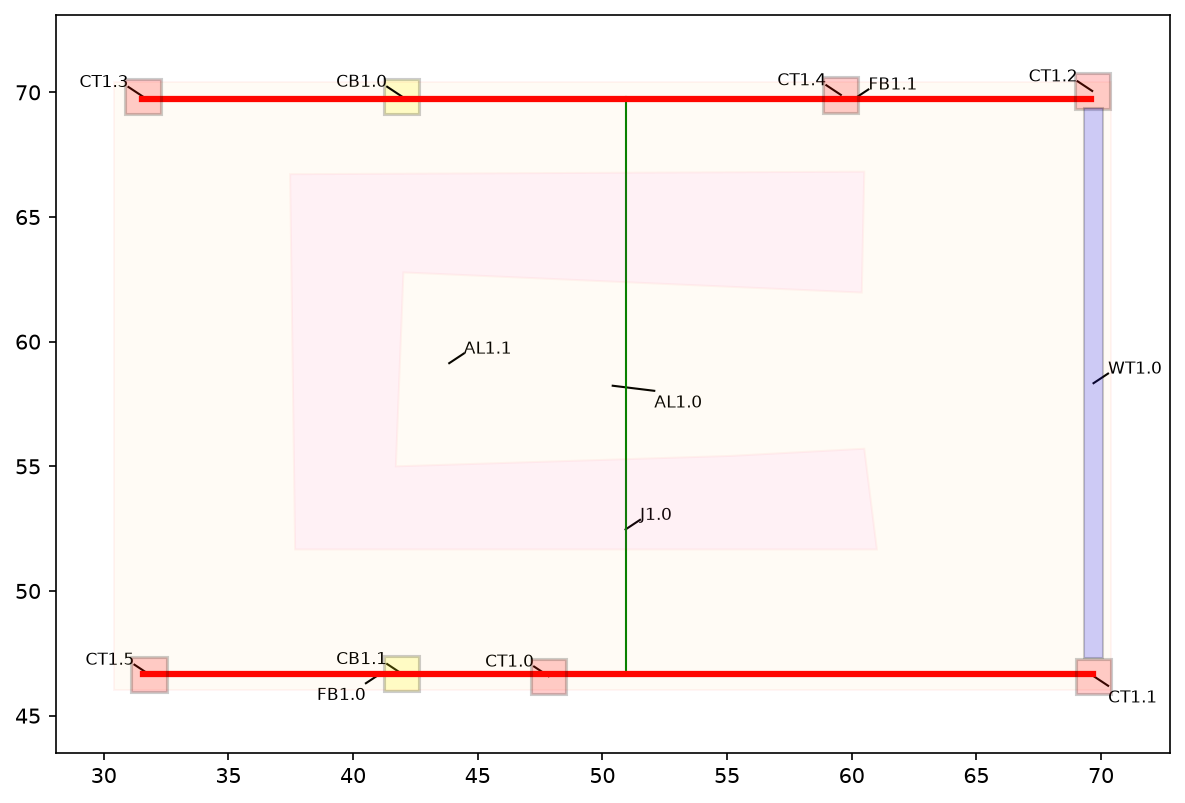

In [4]:
graph.plot_annotations(1)

## 2. Occupancies

loadtracer needs the loads of each occupancy in the drawing, as pressures by load case.
These are the occupancies that the loading areas use:

In [5]:
occupancies_in(graph)

['big stuff', 'residential', 'roof']

The drawing is in feet, so these pressures (psf) give loads in lb/ft and lb.

In [6]:
occupancies = {
    "big stuff": {"D": 50.0, "L": 100.0},
    "residential": {"D": 15.0, "L": 40.0},
    "roof": {"D": 20.0, "S": 35.0},
}

## 3. Run loadtracer

Every element is analysed from the top of the graph down. Only the graph and the occupancies
are needed; element heights and floor elevations are not inputs. `artifacts/` receives the
analysis models (`models.json`) and the reactions (`reaction_forces.json`).

In [7]:
lt = LoadTracer(geometry_graph=graph, occupancies=occupancies)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    quietly(lt.execute_analyses, artifacts_dir="artifacts")

print(f"{len(lt.reactions)} members analysed, {len(lt.errors)} errors")
for w in caught:
    print(f"{type(w.message).__name__}: {w.message}")

55 members analysed, 0 errors


All of the load applied to the building reaches the bottom of the graph:

In [8]:
load_check(lt)

,applied,at the bottom
D,"8,666.48","8,666.48"
S,"6,563.13","6,563.13"
L,"11,832.06","11,832.06"


`lt.issues` lists input that loadtracer corrected so that the rundown could continue
(for example, load drawn past the end of a member, which is moved to the member end):

In [9]:
{tag: issues for tag, issues in lt.issues.items()}

{}

## 4. One member, end to end: `FB2.0`

`FB2.0` carries the `J2.0` joist array. By default loadtracer replaces the joist point
loads with a distributed load. The table shows it both as a line load and as an occupancy
pressure over a trib width, which is the form a hand calculation takes.

In [10]:
pd.DataFrame(lt.converted_joist_loads("FB2.0"))

,member,array,joists,case,dir,profile,start_loc,end_loc,w_start,w_end,total,max_min_ratio,occupancy,pressure,trib_width_start,trib_width_end,approximate
0,FB2.0,J2.0,13,D,FY,uniform,0.00,11.11,215.31,215.31,"2,392.93",1.00,roof,20.00,10.77,10.77,False
1,FB2.0,J2.0,13,S,FY,uniform,0.00,11.11,376.79,376.79,"4,187.63",1.00,roof,35.00,10.77,10.77,False


The loads on `FB2.0` after expansion, by load case:

In [11]:
load_table(lt, "FB2.0")

,kind,source,case,start,end,w_start / P,w_end,total,profile
0,distributed,J2.0,D,0.00,11.11,215.31,215.31,"2,392.93",uniform
1,distributed,J2.0,S,0.00,11.11,376.79,376.79,"4,187.63",uniform


The loads in the Pynite model of `FB2.0`:

In [12]:
member = lt.models["FB2.0"]["members"]["FB2.0"]
pd.DataFrame(member["DistLoads"] + member["PtLoads"])

,0,1,2,3,4,5,6
0,FY,215.31,215.31,0.00,11.11,D,False
1,FY,376.79,376.79,0.00,11.11,S,False


The reactions of `FB2.0` (positive downwards on the supports):

In [13]:
reaction_table(lt, ["FB2.0"])

D        S
member support                  
FB2.0  0       1,196.47 2,093.82
       1       1,196.47 2,093.82

## 5. Joist loads as point loads or distributed loads

With `joist_loads="point"` each joist reaction is applied as a point load, which is the most
detailed representation. The total load is the same either way. Individual reactions are the
same for uniform joist reactions and differ more the more the joist reactions vary; arrays that
vary by 2:1 or more are listed in the warnings in section 3. For those, check the point load
results.

In [14]:
lt_point = LoadTracer(geometry_graph=graph, occupancies=occupancies, joist_loads="point")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    quietly(lt_point.execute_analyses)

pd.concat({"point": load_check(lt_point)["at the bottom"], "distributed": load_check(lt)["at the bottom"]}, axis=1)

,point,distributed
D,"8,666.48","8,666.48"
S,"6,563.13","6,563.13"
L,"11,832.06","11,832.06"


In [15]:
compare_modes(lt_point, lt, ["FB2.0"])

point          distributed          difference      
                      D        S           D        S          D     S
member support                                                        
FB2.0  0       1,196.52 2,093.91    1,196.47 2,093.82      -0.06 -0.10
       1       1,196.41 2,093.72    1,196.47 2,093.82       0.06  0.10

## 6. Reactions at the bottom

The loads delivered to the elements at the bottom of the graph (the foundation):

In [16]:
reaction_table(lt, bottom_members(lt))

,,D,S,L
member,support,,,
WB0.0,0,"1,357.43","2,375.49",0.00
CB0.2,0,-555.67,-683.48,-394.64
CB0.5,0,"1,361.71","1,071.64","1,791.11"
CB0.3,0,"2,952.78","1,705.66","4,728.17"
CB0.0,0,"2,425.06","1,615.36","3,642.06"
CB0.1,0,469.33,-123.20,"1,308.75"
CB0.4,0,655.83,601.65,756.62
